# Dia-Explain - Model Training

Stacking ensemble (RF + XGBoost → LR) with SMOTETomek, threshold tuning on validation,
AUC-ROC + Macro F1 evaluation, 3-fold cross-validation, SHAP global importance.

In [1]:
import pandas as pd
import numpy as np
import joblib
import json
import time
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    precision_recall_curve, make_scorer, f1_score, recall_score,
    brier_score_loss
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier
from lime.lime_tabular import LimeTabularExplainer
import shap

In [2]:
DATA_PATH = "diabetes_012_health_indicators_BRFSS2015.csv"

data = pd.read_csv(DATA_PATH)
feature_cols = [
    'HighBP','HighChol','CholCheck','BMI','Smoker','Stroke',
    'HeartDiseaseorAttack','PhysActivity','Fruits','Veggies',
    'HvyAlcoholConsump','AnyHealthcare','NoDocbcCost','GenHlth',
    'MentHlth','PhysHlth','DiffWalk','Sex','Age','Education','Income'
]
X = data[feature_cols]
y = data["Diabetes_012"]

print("Shape:", data.shape)
print("Class counts:\n", y.value_counts().sort_index())

Shape: (253680, 22)
Class counts:
 Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


In [4]:
# Data quality + BRFSS codebook verification
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

# 1) Binary features must be exactly {0, 1}
BINARY_FEATURES_ALL = [
    'HighBP','HighChol','CholCheck','Smoker','Stroke',
    'HeartDiseaseorAttack','PhysActivity','Fruits','Veggies',
    'HvyAlcoholConsump','AnyHealthcare','NoDocbcCost','DiffWalk','Sex'
]
print("\n--- Binary feature check ---")
for col in BINARY_FEATURES_ALL:
    unique = sorted(data[col].unique())
    ok = set(unique).issubset({0.0, 1.0})
    print(f"  {col:<25} unique={unique}  {'OK' if ok else 'FAIL'}")

# 2) Continuous features within BRFSS ranges
RANGES = {
    'BMI': (12, 98),
    'GenHlth': (1, 5),
    'MentHlth': (0, 30),
    'PhysHlth': (0, 30),
    'Age': (1, 13),
    'Education': (1, 6),
    'Income': (1, 8),
}
print("\n--- Continuous feature range check ---")
for col, (lo, hi) in RANGES.items():
    mn, mx = data[col].min(), data[col].max()
    ok = (mn >= lo) and (mx <= hi)
    print(f"  {col:<10} min={mn:>5} max={mx:>5}  expected [{lo}, {hi}]  {'OK' if ok else 'FAIL'}")

# 3) No raw BRFSS missing-value codes (7/9/77/99/777/999)
MISSING_CODES = {7, 9, 77, 99, 777, 999}
print("\n--- Raw missing-value code check ---")
found_any = False
for col in feature_cols:
    bad = set(data[col].unique()) & MISSING_CODES
    if bad:
        print(f"  WARNING: {col} contains {bad}")
        found_any = True
if not found_any:
    print("  None present.")

# 4) Document absence of BRFSS sampling weights
print("\n--- Sampling weights ---")
print("  Note: BRFSS sampling weights are not included in this dataset.")
print("  Documented as a limitation in the paper.")

Missing values: 0
Duplicate rows: 23899

--- Binary feature check ---
  HighBP                    unique=[np.float64(0.0), np.float64(1.0)]  OK
  HighChol                  unique=[np.float64(0.0), np.float64(1.0)]  OK
  CholCheck                 unique=[np.float64(0.0), np.float64(1.0)]  OK
  Smoker                    unique=[np.float64(0.0), np.float64(1.0)]  OK
  Stroke                    unique=[np.float64(0.0), np.float64(1.0)]  OK
  HeartDiseaseorAttack      unique=[np.float64(0.0), np.float64(1.0)]  OK
  PhysActivity              unique=[np.float64(0.0), np.float64(1.0)]  OK
  Fruits                    unique=[np.float64(0.0), np.float64(1.0)]  OK
  Veggies                   unique=[np.float64(0.0), np.float64(1.0)]  OK
  HvyAlcoholConsump         unique=[np.float64(0.0), np.float64(1.0)]  OK
  AnyHealthcare             unique=[np.float64(0.0), np.float64(1.0)]  OK
  NoDocbcCost               unique=[np.float64(0.0), np.float64(1.0)]  OK
  DiffWalk                  unique=[np.flo

In [5]:
# Stratified train / val / test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42,
    stratify=y_train_full
)
print(f"Train: {X_train.shape[0]}  Val: {X_val.shape[0]}  Test: {X_test.shape[0]}")

Train: 162355  Val: 40589  Test: 50736


In [6]:
counts = y_train.value_counts().sort_index().to_dict()
sampling_strategy = {
    0: counts[0],
    1: min(counts[0] // 4, 60000),
    2: min(counts[0] // 2, 90000),
}
print("Training counts:", counts)
print("SMOTETomek sampling strategy:", sampling_strategy)

rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_leaf=3,
    class_weight="balanced", random_state=42, n_jobs=1
)
xgb = XGBClassifier(
    objective="multi:softprob", num_class=3,
    n_estimators=200, max_depth=6, learning_rate=0.08,
    subsample=0.85, colsample_bytree=0.85,
    eval_metric="mlogloss", random_state=42, n_jobs=1
)
stack = StackingClassifier(
    estimators=[("rf", rf), ("xgb", xgb)],
    final_estimator=LogisticRegression(max_iter=1000),
    passthrough=True, cv=3, n_jobs=1
)
pipeline = ImbPipeline([
    ("scaler", MinMaxScaler()),
    ("resample", SMOTETomek(sampling_strategy=sampling_strategy, random_state=42)),
    ("stack", stack)
])
print(pipeline)

Training counts: {0.0: 136769, 1.0: 2964, 2.0: 22622}
SMOTETomek sampling strategy: {0: 136769, 1: 34192, 2: 68384}
Pipeline(steps=[('scaler', MinMaxScaler()),
                ('resample',
                 SMOTETomek(random_state=42,
                            sampling_strategy={0: 136769, 1: 34192, 2: 68384})),
                ('stack',
                 StackingClassifier(cv=3,
                                    estimators=[('rf',
                                                 RandomForestClassifier(class_weight='balanced',
                                                                        max_depth=10,
                                                                        min_samples_leaf=3,
                                                                        n_jobs=1,
                                                                        random_state=42)),
                                                ('xgb',
                                                 XGBClassi

In [7]:
# Fit raw pipeline once for SHAP extraction
t0 = time.time()
pipeline.fit(X_train, y_train)
print(f"Raw pipeline fitted in {time.time()-t0:.1f} s")

# Wrap in calibration
t0 = time.time()
calibrated = CalibratedClassifierCV(pipeline, method="isotonic", cv=3)
calibrated.fit(X_train, y_train)
print(f"Calibrated wrapper fitted in {time.time()-t0:.1f} s")

Raw pipeline fitted in 507.5 s
Calibrated wrapper fitted in 1832.6 s


In [9]:
val_probs = calibrated.predict_proba(X_val)

def find_best_threshold(y_true, probs, target_class):
    y_bin = (y_true == target_class).astype(int)
    prec, rec, thresh = precision_recall_curve(y_bin, probs[:, target_class])
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    return thresh[np.argmax(f1)]

thresh_1 = float(find_best_threshold(y_val, val_probs, 1))
thresh_2 = float(find_best_threshold(y_val, val_probs, 2))
print(f"Thresholds -> Class 1: {thresh_1:.4f}, Class 2: {thresh_2:.4f}")

def predict_with_thresholds(probs, t1=thresh_1, t2=thresh_2):
    preds = np.full(probs.shape[0], 0)
    preds[probs[:, 1] >= t1] = 1
    preds[probs[:, 2] >= t2] = 2
    return preds

print("predict_with_thresholds defined:", callable(predict_with_thresholds))

Thresholds -> Class 1: 0.0312, Class 2: 0.2316
predict_with_thresholds defined: True


=== Test set (thresholded) ===
              precision    recall  f1-score   support

 No Diabetes       0.93      0.78      0.85     42741
 Prediabetes       0.03      0.09      0.04       926
    Diabetes       0.37      0.62      0.46      7069

    accuracy                           0.74     50736
   macro avg       0.44      0.49      0.45     50736
weighted avg       0.83      0.74      0.78     50736


AUC-ROC macro:    0.757
AUC-ROC weighted: 0.816
  AUC No Diabetes: 0.819
  AUC Prediabetes: 0.630
  AUC Diabetes: 0.823

--- Calibration ---
  Brier class_0: 0.1077
  Brier class_1: 0.0179
  Brier class_2: 0.0983
  Mean Brier: 0.0746
  ECE (10 bins): 0.0070


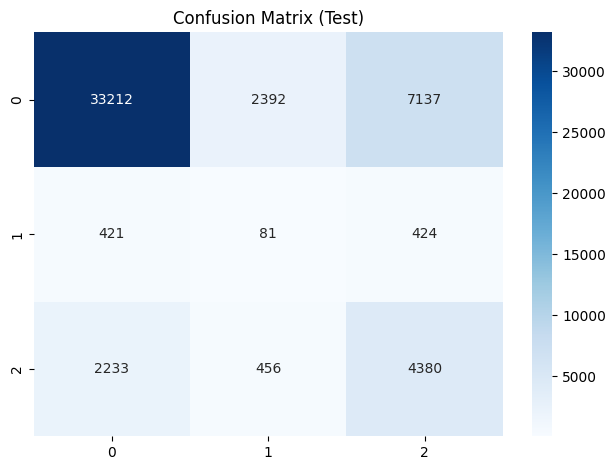

In [10]:
test_probs = calibrated.predict_proba(X_test)
y_pred_test = predict_with_thresholds(test_probs)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

print("=== Test set (thresholded) ===")
print(classification_report(y_test, y_pred_test,
      target_names=["No Diabetes","Prediabetes","Diabetes"]))

auc_macro    = roc_auc_score(y_test_bin, test_probs, multi_class="ovr", average="macro")
auc_weighted = roc_auc_score(y_test_bin, test_probs, multi_class="ovr", average="weighted")
print(f"\nAUC-ROC macro:    {auc_macro:.3f}")
print(f"AUC-ROC weighted: {auc_weighted:.3f}")
for i, name in enumerate(["No Diabetes","Prediabetes","Diabetes"]):
    print(f"  AUC {name}: {roc_auc_score(y_test_bin[:, i], test_probs[:, i]):.3f}")

# --- Calibration metrics ---
print("\n--- Calibration ---")
brier_per_class = {}
for i, c in enumerate([0, 1, 2]):
    y_bin = (y_test == c).astype(int)
    brier_per_class[f"class_{c}"] = brier_score_loss(y_bin, test_probs[:, i])
for k, v in brier_per_class.items():
    print(f"  Brier {k}: {v:.4f}")
mean_brier = np.mean(list(brier_per_class.values()))
print(f"  Mean Brier: {mean_brier:.4f}")

def expected_calibration_error(y_true, y_prob, n_bins=10):
    confidences = y_prob.max(axis=1)
    predictions = y_prob.argmax(axis=1)
    accuracies  = (predictions == y_true).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        in_bin = (confidences > bins[i]) & (confidences <= bins[i+1])
        if in_bin.sum() > 0:
            bin_acc  = accuracies[in_bin].mean()
            bin_conf = confidences[in_bin].mean()
            ece += np.abs(bin_acc - bin_conf) * in_bin.sum() / len(confidences)
    return ece

ece = expected_calibration_error(y_test, test_probs)
print(f"  ECE (10 bins): {ece:.4f}")

cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (Test)")
plt.tight_layout(); plt.show()

In [11]:
def thresholded_macro_f1(y_true, y_probs):
    return f1_score(y_true, predict_with_thresholds(y_probs), average="macro")

def thresh_recall(y_true, y_probs, cls):
    return recall_score(y_true, predict_with_thresholds(y_probs),
                        labels=[cls], average=None)[0]

def macro_auc(y_true, y_probs):
    try:
        yb = label_binarize(y_true, classes=[0, 1, 2])
        return roc_auc_score(yb, y_probs, multi_class="ovr", average="macro")
    except Exception:
        return np.nan

scoring = {
    "macro_f1":  make_scorer(thresholded_macro_f1, response_method="predict_proba"),
    "macro_auc": make_scorer(macro_auc,             response_method="predict_proba"),
    "recall_0":  make_scorer(lambda y, p: thresh_recall(y, p, 0), response_method="predict_proba"),
    "recall_1":  make_scorer(lambda y, p: thresh_recall(y, p, 1), response_method="predict_proba"),
    "recall_2":  make_scorer(lambda y, p: thresh_recall(y, p, 2), response_method="predict_proba"),
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("Running 3-fold CV on calibrated model (slow — ~3x pipeline fit)...")
cv_results = cross_validate(
    calibrated, X_train_full, y_train_full, cv=cv, scoring=scoring,
    n_jobs=1, error_score="raise"
)
print("CV results (mean ± std):")
cv_summary = {}
for m in ["macro_f1","macro_auc","recall_0","recall_1","recall_2"]:
    s = cv_results[f"test_{m}"]
    cv_summary[m] = {"mean": float(np.nanmean(s)), "std": float(np.nanstd(s))}
    print(f"  {m}: {np.nanmean(s):.3f} ± {np.nanstd(s):.3f}")

Running 3-fold CV on calibrated model (slow — ~3x pipeline fit)...
CV results (mean ± std):
  macro_f1: 0.453 ± 0.002
  macro_auc: 0.757 ± 0.001
  recall_0: 0.791 ± 0.010
  recall_1: 0.073 ± 0.010
  recall_2: 0.621 ± 0.004


In [12]:
categorical_features = [
    'HighBP','HighChol','CholCheck','Smoker','Stroke',
    'HeartDiseaseorAttack','PhysActivity','Fruits','Veggies',
    'HvyAlcoholConsump','AnyHealthcare','NoDocbcCost','DiffWalk','Sex'
]
feature_ranges = {
    col: (float(X_train_full[col].min()), float(X_train_full[col].max()))
    for col in feature_cols if col not in categorical_features
}
X_train_sample = X_train_full.sample(n=min(10000, len(X_train_full)), random_state=42)
print("Prep variables created.")

Prep variables created.


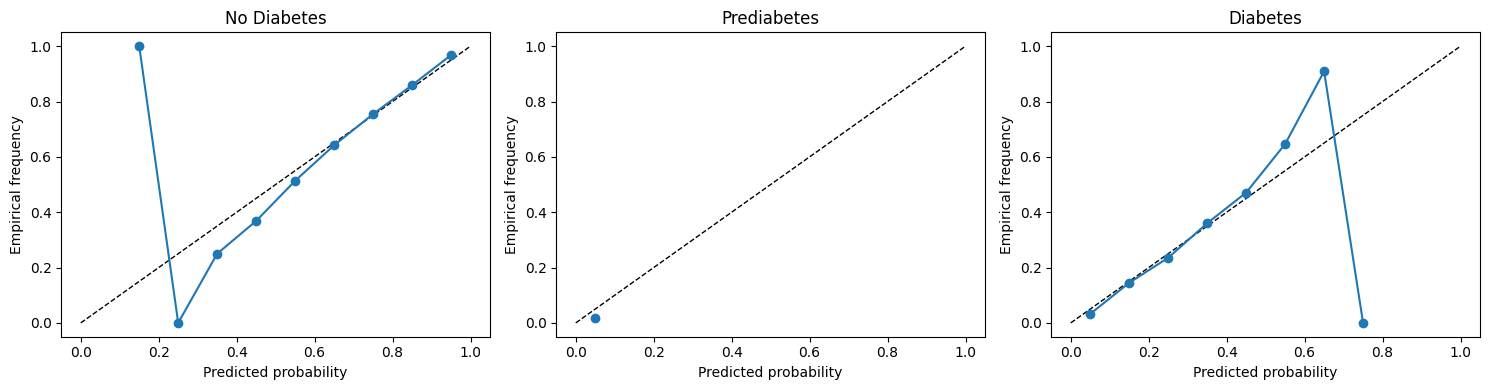

In [13]:
# Reliability diagram
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, name in enumerate(["No Diabetes", "Prediabetes", "Diabetes"]):
    probs_class = test_probs[:, i]
    y_bin = (y_test == i).astype(int)
    bins = np.linspace(0, 1, 11)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    frac_pos = []
    for j in range(len(bins) - 1):
        in_bin = (probs_class > bins[j]) & (probs_class <= bins[j+1])
        if in_bin.sum() > 0:
            frac_pos.append(y_bin[in_bin].mean())
        else:
            frac_pos.append(np.nan)
    axes[i].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[i].plot(bin_centers, frac_pos, 'o-')
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted probability")
    axes[i].set_ylabel("Empirical frequency")
plt.tight_layout(); plt.show()

In [14]:
rng = np.random.default_rng(42)
n_test = len(y_test)
n_boot = 1000
boot_f1, boot_auc = [], []

for _ in range(n_boot):
    idx = rng.choice(n_test, n_test, replace=True)
    y_b = y_test.iloc[idx] if hasattr(y_test, 'iloc') else y_test[idx]
    p_b = y_pred_test[idx]
    probs_b = test_probs[idx]
    boot_f1.append(f1_score(y_b, p_b, average="macro"))
    try:
        yb = label_binarize(y_b, classes=[0, 1, 2])
        if yb.shape[1] == 3:
            boot_auc.append(roc_auc_score(yb, probs_b, multi_class="ovr", average="macro"))
    except Exception:
        pass

ci_f1_low, ci_f1_high = np.percentile(boot_f1, [2.5, 97.5])
ci_auc_low, ci_auc_high = np.percentile(boot_auc, [2.5, 97.5])

print(f"Macro F1  point estimate: {f1_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"Macro F1  95% CI: [{ci_f1_low:.4f}, {ci_f1_high:.4f}]")
print(f"Macro AUC point estimate: {auc_macro:.4f}")
print(f"Macro AUC 95% CI: [{ci_auc_low:.4f}, {ci_auc_high:.4f}]")

bootstrap_results = {
    "f1_ci_low":   float(ci_f1_low),
    "f1_ci_high":  float(ci_f1_high),
    "auc_ci_low":  float(ci_auc_low),
    "auc_ci_high": float(ci_auc_high),
}

Macro F1  point estimate: 0.4493
Macro F1  95% CI: [0.4444, 0.4537]
Macro AUC point estimate: 0.7573
Macro AUC 95% CI: [0.7507, 0.7635]


In [15]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    probs = model.predict_proba(X_te)
    preds = probs.argmax(axis=1)
    f1m = f1_score(y_te, preds, average="macro")
    yb = label_binarize(y_te, classes=[0, 1, 2])
    try:
        aucm = roc_auc_score(yb, probs, multi_class="ovr", average="macro")
    except Exception:
        aucm = float("nan")
    print(f"  {name:<30} macro F1={f1m:.4f}  macro AUC={aucm:.4f}")
    return {"name": name, "macro_f1": float(f1m), "macro_auc": float(aucm)}

baselines = {}

print("--- Baselines (identical preprocessing) ---")
for name, model in [
    ("DummyClassifier",          DummyClassifier(strategy="stratified", random_state=42)),
    ("LogisticRegression",       LogisticRegression(max_iter=1000, random_state=42)),
    ("RandomForest",             RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=1)),
    ("XGBoost",                  XGBClassifier(objective="multi:softprob", num_class=3,
                                               n_estimators=200, max_depth=6, learning_rate=0.08,
                                               eval_metric="mlogloss", random_state=42, n_jobs=1)),
]:
    wrapped = ImbPipeline([
        ("scaler", MinMaxScaler()),
        ("resample", SMOTETomek(sampling_strategy=sampling_strategy, random_state=42)),
        ("model", model),
    ])
    baselines[name] = evaluate_model(name, wrapped, X_train, y_train, X_test, y_test)

# Stacking row
print(f"  {'Stacking (calibrated, argmax)':<30} macro F1={f1_score(y_test, test_probs.argmax(1), average='macro'):.4f}  "
      f"macro AUC={auc_macro:.4f}")
print(f"  {'Stacking (calibrated, thresh)':<30} macro F1={f1_score(y_test, y_pred_test, average='macro'):.4f}  "
      f"macro AUC={auc_macro:.4f}")

baselines["Stacking"] = {
    "name": "Stacking (calibrated, thresh)",
    "macro_f1":  float(f1_score(y_test, y_pred_test, average="macro")),
    "macro_auc": float(auc_macro),
}

--- Baselines (identical preprocessing) ---
  DummyClassifier                macro F1=0.2996  macro AUC=0.4987
  LogisticRegression             macro F1=0.4453  macro AUC=0.7767
  RandomForest                   macro F1=0.4443  macro AUC=0.7776
  XGBoost                        macro F1=0.4160  macro AUC=0.7757
  Stacking (calibrated, argmax)  macro F1=0.3435  macro AUC=0.7573
  Stacking (calibrated, thresh)  macro F1=0.4493  macro AUC=0.7573


In [17]:
import xgboost as xgb

# Extract base learners from the fitted raw pipeline
stack_fitted = pipeline.named_steps["stack"]
base_rf, base_xgb = stack_fitted.estimators_

X_shap = X_test.sample(n=200, random_state=42)


def aggregate_shap(shap_vals, feature_names):
    """Normalise SHAP output across old (list) and new (3D array) formats — used for RF."""
    if isinstance(shap_vals, list):
        stacked = np.stack([np.abs(sv) for sv in shap_vals])   # (classes, n, features)
        mean_abs = stacked.mean(axis=(0, 1))
    elif isinstance(shap_vals, np.ndarray) and shap_vals.ndim == 3:
        mean_abs = np.abs(shap_vals).mean(axis=(0, 2))
    else:
        mean_abs = np.abs(shap_vals).mean(axis=0)
    return dict(zip(feature_names, mean_abs))


def xgb_shap_native(model, X_df):
    """
    Compute exact SHAP values via XGBoost's built-in pred_contribs.
    Returns array of shape (n_samples, n_classes, n_features) — bias column dropped.
    Avoids the SHAP-vs-XGBoost-3.x base_score parsing bug.
    """
    booster = model.get_booster()
    dmat = xgb.DMatrix(X_df, feature_names=list(X_df.columns))
    # strict_shape=True → (n_samples, n_classes, n_features + 1)
    contribs = booster.predict(dmat, pred_contribs=True, strict_shape=True)
    return np.asarray(contribs)[:, :, :-1]


print("Computing SHAP via TreeExplainer (RF) + native pred_contribs (XGB)...")

# --- RF: standard TreeExplainer (works fine) ---
explainer_rf = shap.TreeExplainer(base_rf)
shap_rf = explainer_rf.shap_values(X_shap)
global_rf = aggregate_shap(shap_rf, feature_cols)

# --- XGB: native pred_contribs (avoids base_score parsing bug) ---
shap_xgb_arr = xgb_shap_native(base_xgb, X_shap)           # (n, classes, features)
mean_abs_xgb = np.abs(shap_xgb_arr).mean(axis=(0, 1))      # (features,)
global_xgb = dict(zip(feature_cols, mean_abs_xgb))

# --- Average the two base learners ---
shap_global = {
    f: float((global_rf[f] + global_xgb[f]) / 2) for f in feature_cols
}
shap_global = dict(sorted(shap_global.items(), key=lambda x: x[1], reverse=True))

print("\nTop 10 SHAP features (avg across RF + XGB):")
for feat, val in list(shap_global.items())[:10]:
    print(f"  {feat:<25} {val:.5f}")

Computing SHAP via TreeExplainer (RF) + native pred_contribs (XGB)...

Top 10 SHAP features (avg across RF + XGB):
  GenHlth                   0.21717
  HighBP                    0.10017
  Income                    0.09491
  BMI                       0.08655
  HighChol                  0.07684
  Education                 0.07408
  Age                       0.07295
  PhysHlth                  0.05009
  MentHlth                  0.04205
  Sex                       0.02665


In [18]:
def explanation_fidelity_test(model, X_test, feature_order,
                              categorical_features, n_samples=20):
    """Faithfulness: does |ΔSHAP| correlate with |Δfeature| under perturbation?
    Uses XGBoost's native pred_contribs to avoid the SHAP/XGB-3.x bug."""
    samples = X_test.sample(n=n_samples, random_state=42).reset_index(drop=True)

    # Per-sample top feature from native SHAP
    orig_arr = xgb_shap_native(model, samples)              # (n, classes, features)
    orig_abs = np.abs(orig_arr).mean(axis=1)                # (n, features)
    top_idx = orig_abs.argmax(axis=1)

    deltas, shap_changes = [], []
    for i in range(n_samples):
        col = feature_order[top_idx[i]]
        orig_val = samples.iloc[i][col]

        if col in categorical_features:
            new_val = 1 - orig_val
            abs_delta = abs(new_val - orig_val)
        else:
            new_val = orig_val * 1.10
            abs_delta = abs(new_val - orig_val)

        pert = samples.iloc[[i]].copy().reset_index(drop=True)
        pert[col] = new_val

        pert_arr = xgb_shap_native(model, pert)
        pert_abs = np.abs(pert_arr).mean(axis=1)[0]         # (features,)
        delta_shap = abs(pert_abs[top_idx[i]] - orig_abs[i, top_idx[i]])

        deltas.append(abs_delta)
        shap_changes.append(delta_shap)

    if np.std(deltas) > 1e-9 and np.std(shap_changes) > 1e-9:
        corr, p_val = pearsonr(deltas, shap_changes)
    else:
        corr, p_val = 0.0, 1.0

    print(f"Fidelity test on {n_samples} samples")
    print(f"  Mean |Δfeature|:   {np.mean(deltas):.4f}")
    print(f"  Mean |ΔSHAP|:      {np.mean(shap_changes):.5f}")
    print(f"  Pearson r:         {corr:.4f}  (p = {p_val:.3g})")
    interp = 'faithful (high)' if corr > 0.5 else ('moderate' if corr > 0.2 else 'weak/unstable')
    print(f"  Interpretation:    {interp}")

    return {
        "correlation": float(corr),
        "p_value":     float(p_val),
        "mean_delta_feature": float(np.mean(deltas)),
        "mean_delta_shap":    float(np.mean(shap_changes)),
    }


fidelity_results = explanation_fidelity_test(base_xgb, X_test, feature_cols,
                                              categorical_features, n_samples=20)

Fidelity test on 20 samples
  Mean |Δfeature|:   0.2900
  Mean |ΔSHAP|:      0.02532
  Pearson r:         0.9420  (p = 5.72e-10)
  Interpretation:    faithful (high)


In [19]:
bundle = {
    "model": calibrated,                      # calibrated wrapper — use for prediction
    "raw_pipeline": pipeline,                 # raw pipeline — use for SHAP re-extraction
    "thresholds": {"class_1": float(thresh_1), "class_2": float(thresh_2)},
    "feature_order": feature_cols,
    "categorical_features": categorical_features,
    "feature_ranges": feature_ranges,
    "X_train_sample": X_train_sample,
    "shap_global": shap_global,
    "test_metrics": {
        "auc_macro":       float(auc_macro),
        "auc_weighted":    float(auc_weighted),
        "f1_macro_test":   float(f1_score(y_test, y_pred_test, average="macro")),
        "brier_per_class": {k: float(v) for k, v in brier_per_class.items()},
        "brier_mean":      float(mean_brier),
        "ece":             float(ece),
    },
    "cv_metrics":  cv_summary,
    "bootstrap":   bootstrap_results,
    "baselines":   baselines,
    "fidelity":    fidelity_results,
}

joblib.dump(bundle, "diabetes_model_bundle.pkl")
print("✅ Bundle saved: diabetes_model_bundle.pkl")

# --- Verify reload ---
check = joblib.load("diabetes_model_bundle.pkl")
print("\nReload OK.")
print(f"  Calibrated type:    {type(check['model']).__name__}")
print(f"  Thresholds:         {check['thresholds']}")
print(f"  AUC macro:          {check['test_metrics']['auc_macro']:.4f}")
print(f"  AUC macro 95% CI:   [{check['bootstrap']['auc_ci_low']:.4f}, {check['bootstrap']['auc_ci_high']:.4f}]")
print(f"  Macro F1:           {check['test_metrics']['f1_macro_test']:.4f}")
print(f"  Macro F1 95% CI:    [{check['bootstrap']['f1_ci_low']:.4f}, {check['bootstrap']['f1_ci_high']:.4f}]")
print(f"  Brier (mean):       {check['test_metrics']['brier_mean']:.4f}")
print(f"  ECE:                {check['test_metrics']['ece']:.4f}")
print(f"  SHAP features:      {len(check['shap_global'])}")
print(f"  Fidelity r:         {check['fidelity']['correlation']:.4f}")
print(f"  Baselines tracked:  {list(check['baselines'].keys())}")

✅ Bundle saved: diabetes_model_bundle.pkl

Reload OK.
  Calibrated type:    CalibratedClassifierCV
  Thresholds:         {'class_1': 0.031248949965973095, 'class_2': 0.23159611871748909}
  AUC macro:          0.7573
  AUC macro 95% CI:   [0.7507, 0.7635]
  Macro F1:           0.4493
  Macro F1 95% CI:    [0.4444, 0.4537]
  Brier (mean):       0.0746
  ECE:                0.0070
  SHAP features:      21
  Fidelity r:         0.9420
  Baselines tracked:  ['DummyClassifier', 'LogisticRegression', 'RandomForest', 'XGBoost', 'Stacking']
